# Yaw controller: reinforcement learning (SAC) for the rotation

**Advanced task: rotate the drone on itself at the top of the flight.** The policy is trained **only on
the yaw model we identified** in `4_identification_yaw.ipynb` (never on `quadcopter_model.p`).

**Option A of the plan**: the altitude policy (`3_rl_controller.ipynb`, `models/sac_nn.zip`) is kept
**unchanged** and keeps the collective thrust `u_T`. A second, independent SAC policy controls the
differential command `u_yaw`. A fixed mixer builds the 4 motor commands:

```
 altitude policy --- u_T ----+
                             +--> mixer:  u1 = u3 = u_T + u_yaw,   u2 = u4 = u_T - u_yaw  --> 4 motors
 yaw policy ------- u_yaw ---+            (u_yaw clipped to +-(1 - |u_T|): thrust has priority)

            +---------------- identified yaw model (Python) ----------------+
 u_yaw ---> | NN  w_dot_z[k+1] = F(w_dot_z[k], u_yaw[k], u_T[k])            | -> integrate -> wz, psi
 u_T   ---> |                                                               |
            +---------------------------------------------------------------+
```

| choice | what | why |
|---|---|---|
| plant | yaw NN of notebook 4, **randomised** | free-run error 0.19 rad/s² (noise floor 0.07); model C (tanh) kept as an independent test drone and for the PD baseline |
| algorithm | **SAC** | same reasons as for the altitude: continuous command, sample-efficient, smooth policies |
| action | `u_yaw` itself, in [-0.1, 0.1] | the identified range; 0.04 already gives a fast quarter turn, so a [-1, 1] action would waste resolution |
| observation | heading error, `wz`, `w_dot_z_prev`, `u_yaw_prev`, error integral, `u_T` | the state of the model with its delay (Markov); `u_T` because the yaw gain depends on the thrust; no absolute angle (the dynamics do not depend on it) |
| reward | tracking + precision + no violent spinning + smooth command | see section 2.3 |
| robustness | domain randomisation: model, thrust profile, references, initial rate, process and sensor noise | the policy must survive the model -> simulator gap |

All the code of the environment is in `yaw_env.py`; this notebook explains it, trains, evaluates and exports.

## 0. Setup

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt, torch
torch.set_num_threads(1)
from stable_baselines3 import SAC
from yaw_env import (YawEnv, YawPD, YawTanhPlant, rollout, yaw_mission, random_yaw_mission, random_thrust,
                     hover_thrust, load_yaw_plant, load_yaw_test_plant,
                     Ts, N_STEPS, YAW_MAX, U_HOVER, T_YAW, OBS_NAMES)
np.set_printoptions(suppress=True, precision=4)
os.makedirs('figures', exist_ok=True)
C_SAC, C_PD, C_REF, C_MUTED = '#2a78d6', '#eb6834', '#52514e', '#8a8984'
BASE_NOISE = {'psi': 0.005, 'wz': 0.02, 'w': 0.7}      # about g_noise = 0.1 (the MATLAB evaluation level)

## 1. The plants: our identified yaw models

**Training plant - yaw NN** (`models/yaw_model_nn.joblib`): $\dot w_z[k+1] = F(\dot w_z[k], u_{yaw}[k], u_T[k])$,
MLP 3 -> 16 tanh -> 1, run in numpy by `yaw_env.YawNNPlant`. `u_T` is clipped to the identified range
[0, 0.8] before entering the network (no extrapolation).

**Test drone - model C**: $\dot w_z[k+1] = a\,\dot w_z[k] + b\,[\tanh(\beta(u_T+u_{yaw})) - \tanh(\beta(u_T-u_{yaw}))] + c$,
3 parameters, identified independently by least squares. It is *not* used for training: like the tanh
model for the altitude, it plays "another drone" to test whether the policy transfers. Its gain, linearised
at $u_{yaw}=0$, is also what the PD baseline inverts.

The figure shows the two properties every controller must deal with: the **gain falls with the thrust**
(left), and there is **no yaw drag**: under a constant command `w_dot_z` settles to a constant, so `wz`
keeps growing (right). The drone must be actively braked at the end of every turn.

model C: tau = 0.200 s, gain at hover = 173.5 rad/s^2 per unit of u_yaw
fastest quarter turn at |u_yaw| = 0.1 (bang-bang, ignoring the lag): 0.60 s


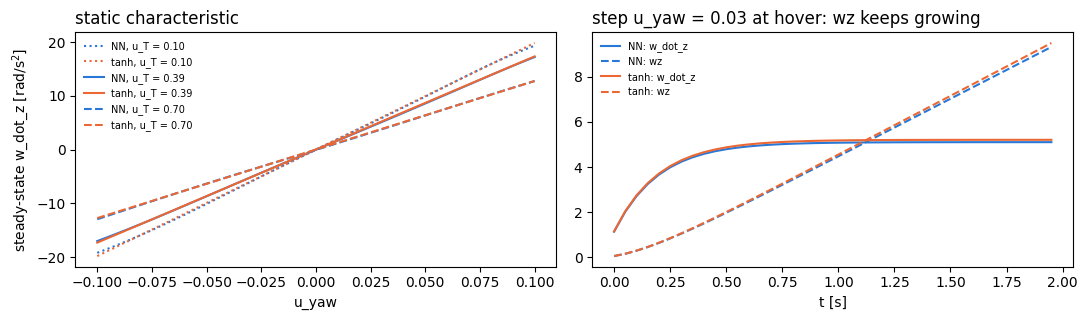

In [2]:
nn_p, tanh_p = load_yaw_plant(), load_yaw_test_plant()
print(f'model C: tau = {tanh_p.tau:.3f} s, gain at hover = {tanh_p.gain(U_HOVER):.1f} rad/s^2 per unit of u_yaw')
print(f'fastest quarter turn at |u_yaw| = {YAW_MAX} (bang-bang, ignoring the lag): '
      f'{2 * np.sqrt((np.pi / 2) / (tanh_p.gain(U_HOVER) * YAW_MAX)):.2f} s')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ug = np.linspace(-YAW_MAX, YAW_MAX, 41)
for uT, ls in ((0.1, ':'), (U_HOVER, '-'), (0.7, '--')):
    for p, c in ((nn_p, C_SAC), (tanh_p, C_PD)):
        st = []
        for u in ug:
            p.reset()
            for _ in range(100): p.step(u, uT)
            st.append(p.w)
        ax[0].plot(ug, st, ls, color=c, label=f'{"NN" if p is nn_p else "tanh"}, u_T = {uT:.2f}')
ax[0].set_xlabel('u_yaw'); ax[0].set_ylabel('steady-state w_dot_z [rad/s$^2$]'); ax[0].legend(fontsize=7, frameon=False)
ax[0].set_title('static characteristic', loc='left')
tt = np.arange(40) * Ts
for p, c, n in ((nn_p, C_SAC, 'NN'), (tanh_p, C_PD, 'tanh')):
    p.reset(); w = [p.step(0.03, U_HOVER) for _ in tt]
    wz = np.cumsum(w) * Ts
    ax[1].plot(tt, w, color=c, label=f'{n}: w_dot_z'); ax[1].plot(tt, wz, '--', color=c, label=f'{n}: wz')
ax[1].set_xlabel('t [s]'); ax[1].set_title('step u_yaw = 0.03 at hover: wz keeps growing', loc='left')
ax[1].legend(fontsize=7, frameon=False); plt.tight_layout(); plt.show()

## 2. The environment (`yaw_env.YawEnv`)

### 2.1 Mission, timing, thrust
The full flight becomes **13 s** (`N_STEPS = 260`): 0-1 s on the platform, 1-2 s climb to 0.5 m,
then **four quarter turns every 2 s** (90°, 180°, 270°, 360° at t = 2, 4, 6, 8 s), landing from 10 s.
The heading reference is **unwrapped**: the last step is $2\pi$ (a full turn), not 0, otherwise the
controller would take the short way back. (The simulator's `psi` is also continuous, notebook 4.)
Thresholds are shifted by $T_s/2$, as for the altitude.

Measurements, chosen like the altitude loop of `EINT_RL_closed_loop.slx`: `psi`, `wz` sampled at $t_k$;
`w_dot_z_prev` and `u_yaw_prev` through Unit Delays (0 at $k = 0$); `u_T` is the thrust of the altitude
policy at the same step. Kinematics: trapezoid rule (the one that matches the simulator, notebook 4).

**Thrust seen by the yaw policy.** In training, `u_T` is a random staircase (70 % near hover, 30 %
anywhere in [0, 0.8], sometimes motors off at the start): the yaw policy must work whatever the
altitude policy does. In evaluation: motors off at $t=0$, then hover.

**Mixer.** The action is `u_yaw` in [-0.1, 0.1]; the mixer clips it to $\pm(1-|u_T|)$, so no motor
command leaves [-1, 1] and the thrust (= not crashing) always has priority.

### 2.2 Observation (identical in MATLAB later)
$$o = [\,e,\ w_z/5,\ \dot w_{z,prev}/20,\ u_{yaw,prev}/0.1,\ I/I_{max},\ u_T\,],\qquad e = \psi_{ref}-\psi\ (\text{clipped } \pm\pi),\quad
I_k = \mathrm{clip}(I_{k-1}+T_s e_k,\ \pm 0.5)$$
$(w_z, \dot w_{z,prev}, u_{yaw,prev}, u_T)$ is the state of the identified model with its one-sample delay:
the problem is Markov. There is **no absolute angle**: the dynamics are the same at any heading, so the
policy only needs the error (and generalises to any target). The integral removes the static error
caused by a residual torque (the NN has a bias of about -0.01 rad/s² at rest; real motors are never
perfectly matched).

### 2.3 Reward (per step)
$$r = 1 - |e|/\pi - 0.5\,(1-e^{-(e/0.05)^2}) - 0.01\,w_z^2 - 0.2\,(\Delta u_{yaw}/0.1)^2$$
- $1-|e|/\pi$: alive bonus + tracking ($r > 0$ in normal flight);
- the Gaussian term rewards *precision* (within ~3°), which $|e|$ alone barely does;
- $w_z^2$: no violent spinning (a quarter turn needs ~2-3 rad/s; the penalty only bites far beyond);
- $\Delta u_{yaw}^2$: smooth command, essential with sensor noise;
- termination with -50 if $|w_z| > 15$ rad/s (spinning out of control).

### 2.4 Domain randomisation (training only)
| what | range |
|---|---|
| time constant (speed of the motors) | x [0.8, 1.25] |
| yaw authority (gain) | x [0.85, 1.15] |
| residual torque | ± 0.3 rad/s² |
| process noise on `w_dot_z` | std up to 0.2 rad/s² |
| sensor noise `psi` / `wz` / `w_dot_z` | std up to 0.01 rad / 0.1 rad/s / 1.0 rad/s² |
| references | 40 % the mission, 60 % random staircases (mostly ±90° / ±180°, some arbitrary angles) |
| thrust | random staircase (see 2.1) |
| initial state | 30 % already turning (`wz` in ±2 rad/s) |

observation : {'e': np.float32(0.0), 'wz/5': np.float32(0.0), 'w_dot_z_prev/20': np.float32(0.0), 'u_yaw_prev/YAW_MAX': np.float32(0.0), 'I/I_MAX': np.float32(0.0), 'u_T': np.float32(0.0)}
measurements: {'t': 0.0, 'psi': 0.0, 'wz': 0.0, 'w_dot_z_prev': 0.0, 'u_yaw_prev': 0.0, 'u_T': 0.0, 'psi_ref': 0.0}


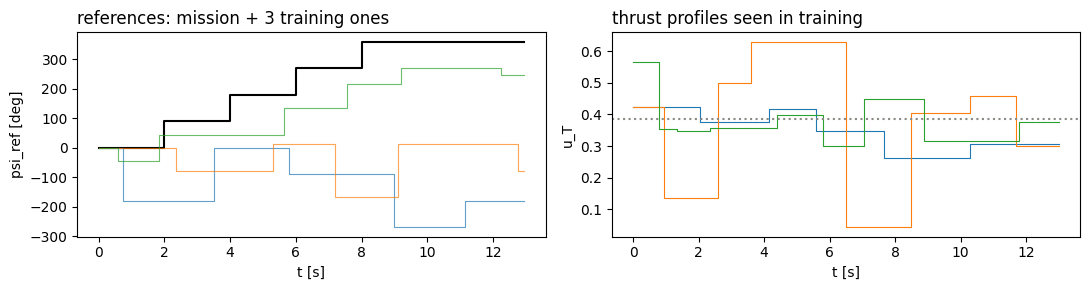

In [3]:
env = YawEnv(plant=nn_p)
obs, info = env.reset(seed=0)
print('observation :', dict(zip(OBS_NAMES, obs.round(3))))
print('measurements:', {k: round(v, 3) for k, v in info['m'].items()})

rng = np.random.default_rng(3)
tt = np.arange(N_STEPS) * Ts
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].step(tt, np.degrees([yaw_mission(t) for t in tt]), where='post', color='k', label='mission')
for j in range(3):
    f = random_yaw_mission(rng); ax[0].step(tt, np.degrees([f(t) for t in tt]), where='post', lw=.8, alpha=.7)
ax[0].set_ylabel('psi_ref [deg]'); ax[0].set_xlabel('t [s]'); ax[0].set_title('references: mission + 3 training ones', loc='left')
for j in range(3):
    ax[1].step(np.arange(N_STEPS + 1) * Ts, random_thrust(rng), where='post', lw=.8)
ax[1].axhline(U_HOVER, color=C_MUTED, ls=':'); ax[1].set_ylabel('u_T'); ax[1].set_xlabel('t [s]')
ax[1].set_title('thrust profiles seen in training', loc='left'); plt.tight_layout(); plt.show()

### 2.5 Linear baseline
A **PD + integral with feedback linearisation**: $\dot w_{z,cmd} = K_p e - K_d w_z + K_i\!\int e$, then
$u_{yaw} = (\dot w_{z,cmd} - c_0)/G(u_T)$ with $G$ the gain of model C at the current thrust, so the loop
behaves the same at any thrust. Gains grid-searched on both models under the constraint *overshoot
< 5°*: $K_p = 12,\ K_d = 8,\ K_i = 2$. It uses exactly the measurements the policy has.

In [4]:
def pd_controller():
    pd = YawPD()
    def c(obs, m):
        if m['t'] == 0:
            pd.reset()
        return pd(m)
    return c

o = rollout(YawEnv(plant=nn_p), pd_controller())
print(f"PD on the NN model: RMSE {o['rmse_deg']:.1f} deg, settling (5 deg) per quarter turn {o['settle_s']} s, "
      f"overshoot {o['overshoot_deg'].round(1)} deg")

PD on the NN model: RMSE 31.8 deg, settling (5 deg) per quarter turn [1.6 1.6 1.6 1.6] s, overshoot [4.6 4.6 4.6 4.7] deg


## 3. Training (SAC)

Same hyper-parameters as the altitude policy (`train_sac_yaw.py` is the terminal version:
`python train_sac_yaw.py 150000 <seed>`). `EvalCallback` keeps the checkpoint with the best return on
**perturbed models + noise** on the rotation mission, not the best on the nominal model.

The problem is smaller than the altitude one (one axis, no ground, no take-off transient):
150 k steps (about 2 h of simulated flight) are enough; follow it with `tensorboard --logdir runs/tb`.

`TRAIN = False` loads `models/sac_yaw.zip` if it exists (otherwise it trains). `TRAIN = True` retrains and
overwrites it.

In [5]:
TRAIN = not os.path.isfile('models/sac_yaw.zip')
STEPS = 150_000
if TRAIN:
    import shutil
    from stable_baselines3.common.monitor import Monitor
    from stable_baselines3.common.callbacks import EvalCallback
    train_env = Monitor(YawEnv(plant=nn_p, randomize=True))
    eval_env = Monitor(YawEnv(plant=nn_p, randomize=True, fig_prob=1.0))
    agent = SAC('MlpPolicy', train_env, seed=0, learning_rate=3e-4, buffer_size=300_000, batch_size=256,
                gamma=0.98, tau=0.005, learning_starts=5_000, policy_kwargs=dict(net_arch=[128, 128]),
                tensorboard_log='runs/tb')
    agent.learn(STEPS, tb_log_name='sac_yaw_s0',
                callback=EvalCallback(eval_env, n_eval_episodes=20, eval_freq=10_000, deterministic=True,
                                      best_model_save_path='runs/sac_yaw_s0', log_path='runs/sac_yaw_s0'))
    shutil.copy('runs/sac_yaw_s0/best_model.zip', 'models/sac_yaw.zip')
agent = SAC.load('models/sac_yaw.zip', device='cpu')
print(agent.policy.actor)

Actor(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (latent_pi): Sequential(
    (0): Linear(in_features=6, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
  )
  (mu): Linear(in_features=128, out_features=1, bias=True)
  (log_std): Linear(in_features=128, out_features=1, bias=True)
)


In [ ]:
# learning curve (evaluation return on perturbed models + noise, rotation mission)
f = 'runs/sac_yaw_s0/evaluations.npz'
if os.path.isfile(f):
    d = np.load(f); m, sd = d['results'].mean(1), d['results'].std(1)
    plt.figure(figsize=(8, 3))
    plt.plot(d['timesteps'] / 1e3, m, color=C_SAC); plt.fill_between(d['timesteps'] / 1e3, m - sd, m + sd, color=C_SAC, alpha=.15, lw=0)
    plt.xlabel('training steps [k]'); plt.ylabel('evaluation return'); plt.title('SAC yaw: learning curve', loc='left')
    plt.tight_layout(); plt.show()

## 4. Evaluation

Two flights, SAC against the PD: on the **training model** (the NN, nominal) and on the **tanh model**, which the policy has never seen: the same question as model -> simulator. Robustness to sensor noise is then checked on the real simulator, in MATLAB (`g_noise`).

Metrics: RMSE of the heading (dominated by the steps themselves, which no controller can follow
instantly), **settling time** of each quarter turn (to within 5° for good), **overshoot**, final error,
and the rms of $\Delta u_{yaw}$ (command smoothness, i.e. motor wear).

In [ ]:
sac_controller = lambda obs, m: float(agent.predict(obs, deterministic=True)[0][0])

def compare(plant, noise=None, thrust=None, seed=0):
    env = YawEnv(plant=plant, noise=noise, thrust=thrust)
    return {'SAC': rollout(env, sac_controller, seed), 'PD': rollout(env, pd_controller(), seed)}

cases = [('NN nominal', compare(nn_p)),
         ('tanh (never seen)', compare(tanh_p))]

fig, ax = plt.subplots(4, len(cases), figsize=(4.6 * len(cases), 8.5), sharex=True,
                       gridspec_kw={'height_ratios': [2, 1, 1, 1]}, squeeze=False)
for j, (title, res) in enumerate(cases):
    a = ax[0, j]
    a.step(res['SAC']['t'], np.degrees(res['SAC']['psi_ref']), '--', where='post', color=C_REF, lw=1.1, label='reference')
    for k, c in (('PD', C_PD), ('SAC', C_SAC)):
        a.plot(res[k]['t'], np.degrees(res[k]['psi']), color=c, label=f"{k}  RMSE {res[k]['rmse_deg']:.1f} deg")
    a.set_title(title, loc='left', fontsize=10); a.set_ylabel('psi [deg]'); a.legend(fontsize=7, frameon=False)
    for k, c in (('PD', C_PD), ('SAC', C_SAC)):
        ax[1, j].step(res[k]['t'], res[k]['u'], where='post', color=c, lw=1)
        ax[2, j].plot(res[k]['t'], res[k]['wz'], color=c, lw=1)
    ax[3, j].step(res['SAC']['t'], res['SAC']['u_T'], where='post', color=C_MUTED)
    ax[1, j].set_ylabel('u_yaw'); ax[2, j].set_ylabel('wz [rad/s]'); ax[3, j].set_ylabel('u_T'); ax[3, j].set_xlabel('t [s]')
plt.tight_layout(); plt.savefig('figures/yaw_flights.png', dpi=150); plt.show()

print(f'{"case":20s} {"":4s} {"RMSE":>7s} {"settle per quarter turn [s]":>30s} {"max overshoot":>14s} {"final err":>10s} {"du rms":>8s}')
for title, res in cases:
    for k in ('SAC', 'PD'):
        o = res[k]
        print(f"{title:20s} {k:4s} {o['rmse_deg']:6.1f}° {str(o['settle_s']):>30s} {np.nanmax(o['overshoot_deg']):13.1f}° "
              f"{o['final_err_deg']:9.2f}° {o['du_rms']:8.4f}")

## 5. Export to MATLAB: the full mission

The yaw policy is not flown alone in MATLAB: it flies **with the altitude policy**, through the mixer.
`full_mission.py` flies the full mission (take-off, four quarter turns at 0.5 m, landing) on the identified
models and writes into `../rl_interface_yaw/` the two policies (`policy.mat`, `policy_yaw.mat`) and the
reference flight `traj_full.mat`:

```
cd python;  python full_mission.py
```

Then in MATLAB, `rl_interface_yaw/EINT_RL_eval_yaw` checks that `rl_controller_full.m` computes exactly
what Python computes, and flies the mission on the simulator.

## 6. Critical analysis (to complete with the results above)

* **Where RL can win.** Without yaw drag, every turn is "push, then brake". The PD brakes in proportion
  to `wz`; the policy sees `w_dot_z_prev` and `u_yaw_prev`, i.e. the motor lag, so it can start braking
  earlier and settle faster for the same overshoot. Compare the settling times of section 4.1.
* **Transfer.** The tanh flight of section 4 is the honest check of how the policy behaves on a drone it was not trained on, the same question as model -> `UAV_model.slx`.
* **Coupling with the altitude.** Notebook 4 measured that `u_yaw` costs about 0.01 m/s² of vertical
  acceleration at `u_yaw = 0.05`: negligible for the altitude policy, which was trained with ±0.4 m/s²
  offsets. The other direction is handled here: the gain changes with `u_T`, and `u_T` is in the
  observation.
* **Limits.** The model is valid for `u_T` in [0, 0.8] and `|u_yaw| <= 0.1` (the data). During take-off
  the altitude policy may use full thrust: the yaw margin $1-|u_T|$ then shrinks to 0, and the mixer
  gives priority to the thrust. The heading is held at 0 during take-off, so this costs nothing as
  long as the turns happen in hover.
* **If MATLAB disagrees with Python**: the replay check of `EINT_RL_eval_yaw.m` proves the controller code
  is identical, so any difference comes from the model (model-reality gap).